Generating CAPTCHA dataset...
Dataset shape: (5000, 40, 120, 1)
Labels shape: (5000,)


C:\Users\sahil\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 38, 118, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 19, 59, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 17, 57, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 28, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 6, 26, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 13, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4992)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       639,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 736,420 (2.81 MB)

 Trainable params: 736,420 (2.81 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 23s 300ms/step - accuracy: 0.0306 - loss: 3.5850 - val_accuracy: 0.0300 - val_loss: 3.5784
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 14s 237ms/step - accuracy: 0.0744 - loss: 3.3815 - val_accuracy: 0.2250 - val_loss: 2.6566
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 13s 232ms/step - accuracy: 0.2644 - loss: 2.3906 - val_accuracy: 0.5075 - val_loss: 1.4780
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 13s 228ms/step - accuracy: 0.4008 - loss: 1.7150 - val_accuracy: 0.6450 - val_loss: 1.0096
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 13s 230ms/step - accuracy: 0.5131 - loss: 1.3174 - val_accuracy: 0.7550 - val_loss: 0.7684
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 13s 231ms/step - accuracy: 0.5928 - loss: 1.0571 - val_accuracy: 0.8375 - val_loss: 0.5586
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 15s 255ms/step - accuracy: 0.6647 - loss: 0.8572 - val_accuracy: 0.8650 - val_loss: 0.4185
Epoch 8/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 15s 267ms/step - accuracy: 0.7144 - loss: 0.7150 - val_accu

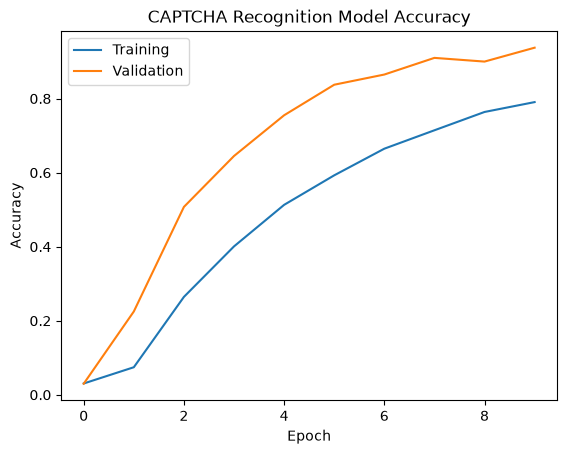


Actual CAPTCHA: 5YML
Predicted First Character: 5


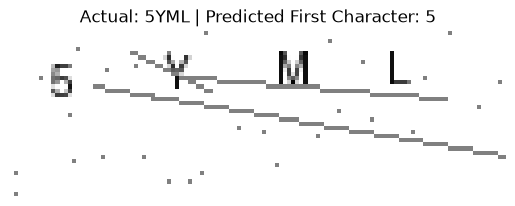

In [1]:
import numpy as np
import random
import string
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw, ImageFont
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

IMG_WIDTH = 120
IMG_HEIGHT = 40
CHARACTERS = string.ascii_uppercase + string.digits
NUM_CLASSES = len(CHARACTERS)

SAMPLES = 5000

# ------------------------------------------------------------
# 2. GENERATE SYNTHETIC CAPTCHA IMAGES
# ------------------------------------------------------------

def generate_captcha():
    text = ''.join(random.choices(CHARACTERS, k=4))

    image = Image.new("RGB", (IMG_WIDTH, IMG_HEIGHT), "white")
    draw = ImageDraw.Draw(image)

    # Draw CAPTCHA characters
    for i, char in enumerate(text):
        x = 10 + i * 27
        y = random.randint(3, 10)

        draw.text((x, y), char, fill="black")

    # Add noise lines
    for _ in range(3):
        x1 = random.randint(0, IMG_WIDTH)
        y1 = random.randint(0, IMG_HEIGHT)
        x2 = random.randint(0, IMG_WIDTH)
        y2 = random.randint(0, IMG_HEIGHT)

        draw.line((x1, y1, x2, y2), fill="gray", width=1)

    # Add random dots
    for _ in range(30):
        x = random.randint(0, IMG_WIDTH - 1)
        y = random.randint(0, IMG_HEIGHT - 1)
        draw.point((x, y), fill="gray")

    return np.array(image), text


# ------------------------------------------------------------
# 3. CREATE DATASET
# ------------------------------------------------------------

X = []
Y = []

print("Generating CAPTCHA dataset...")

for _ in range(SAMPLES):

    image, text = generate_captcha()

    # Convert image to grayscale
    image = Image.fromarray(image).convert("L")

    image = np.array(image)

    # Normalize pixel values
    image = image / 255.0

    X.append(image)

    # Store first character as classification target
    Y.append(CHARACTERS.index(text[0]))

X = np.array(X)
Y = np.array(Y)

# Add channel dimension
X = X.reshape(-1, IMG_HEIGHT, IMG_WIDTH, 1)

print("Dataset shape:", X.shape)
print("Labels shape:", Y.shape)


# ------------------------------------------------------------
# 4. SPLIT DATASET
# ------------------------------------------------------------

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42
)

# Convert labels to categorical format
Y_train = to_categorical(Y_train, NUM_CLASSES)
Y_test = to_categorical(Y_test, NUM_CLASSES)


# ------------------------------------------------------------
# 5. BUILD CNN MODEL
# ------------------------------------------------------------

model = Sequential([

    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(IMG_HEIGHT, IMG_WIDTH, 1)
    ),

    MaxPooling2D((2, 2)),

    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    MaxPooling2D((2, 2)),

    Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),

    Dropout(0.5),

    Dense(NUM_CLASSES, activation="softmax")
])


# ------------------------------------------------------------
# 6. COMPILE MODEL
# ------------------------------------------------------------

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


# ------------------------------------------------------------
# 7. TRAIN MODEL
# ------------------------------------------------------------

history = model.fit(
    X_train,
    Y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)


# ------------------------------------------------------------
# 8. EVALUATE MODEL
# ------------------------------------------------------------

loss, accuracy = model.evaluate(
    X_test,
    Y_test,
    verbose=0
)

print("\nTest Accuracy:", accuracy)


# ------------------------------------------------------------
# 9. PLOT TRAINING ACCURACY
# ------------------------------------------------------------

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("CAPTCHA Recognition Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend(["Training", "Validation"])
plt.show()


# ------------------------------------------------------------
# 10. TEST THE MODEL
# ------------------------------------------------------------

test_image, actual_text = generate_captcha()

gray_image = Image.fromarray(test_image).convert("L")

processed_image = np.array(gray_image) / 255.0

processed_image = processed_image.reshape(
    1,
    IMG_HEIGHT,
    IMG_WIDTH,
    1
)

prediction = model.predict(processed_image, verbose=0)

predicted_index = np.argmax(prediction)

predicted_character = CHARACTERS[predicted_index]

print("\nActual CAPTCHA:", actual_text)
print("Predicted First Character:", predicted_character)


# ------------------------------------------------------------
# 11. DISPLAY CAPTCHA
# ------------------------------------------------------------

plt.imshow(test_image)
plt.axis("off")
plt.title(
    "Actual: " + actual_text +
    " | Predicted First Character: " +
    predicted_character
)

plt.show()